# Домашнее задание. Анализ климатических данных. Временные ряды

**Датасет:** [Climate Change: Earth Surface Temperature Data](https://www.kaggle.com/datasets/berkeleyearth/climate-change-earth-surface-temperature-data) (Berkeley Earth), файл `GlobalLandTemperaturesByCountry.csv`.

**Цель:** построить базовый прогноз среднемесячной температуры для выбранной страны (Беларусь) и оценить его качество метриками MAE, RMSE, MAPE.

**Пайплайн:** подготовка ряда → holdout-разбиение 80/20 → rolling-window backtesting → генерация признаков (лаги + календарь) → линейная регрессия → метрики.

## 1. Подготовка данных

Загружаем датасет `GlobalLandTemperaturesByCountry.csv`, фильтруем наблюдения по Беларуси и строим временной ряд средних месячных температур с индексом-датой.

In [13]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# В pandas 3.x infer_freq выводит информационное предупреждение об изменении
# поведения в будущих версиях — на результаты оно не влияет, скрываем его
warnings.filterwarnings('ignore', message='.*infer_freq.*')

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True

DATA_PATH = '../data/GlobalLandTemperaturesByCountry.csv'
COUNTRY = 'Belarus'


In [14]:
# Загружаем датасет и фильтруем по стране
df = pd.read_csv(DATA_PATH)
df_country = (
    df.loc[df['Country'] == COUNTRY, ['dt', 'AverageTemperature']]
      .assign(dt=lambda x: pd.to_datetime(x['dt']))
      .set_index('dt')
      .sort_index()
      .rename(columns={'AverageTemperature': 'temperature'})
)

print(f'Страна: {COUNTRY}')
print(f'Количество наблюдений: {len(df_country)}')
print(f'Период: {df_country.index.min().date()} — {df_country.index.max().date()}')
print(f'Частота ряда (infer_freq): {pd.infer_freq(df_country.index)}')
print(f'Пропусков всего: {df_country["temperature"].isna().sum()}')
print('\nРаспределение пропусков по десятилетиям:')
nans = df_country[df_country['temperature'].isna()]
print(nans.groupby(nans.index.year // 10 * 10).size())

Страна: Belarus
Количество наблюдений: 3239
Период: 1743-11-01 — 2013-09-01
Частота ряда (infer_freq): MS
Пропусков всего: 73

Распределение пропусков по десятилетиям:
dt
1740    61
1750    11
2010     1
dtype: int64


Пропуски сосредоточены в 1740–1750-х годах (ранние измерения) — данные этого периода неполные. С 1900 года ряд полный, поэтому для анализа берём период **с января 1900 года** и удаляем единственный пропуск в конце ряда.

In [15]:
# Берём период с 1900 года и убираем пропуски (остался один — последний месяц)
ts = df_country.loc['1900':].dropna().copy()
ts = ts.asfreq('MS')  # фиксируем месячную частоту индекса

print(f'Итоговый ряд: {len(ts)} наблюдений, {ts.index.min().date()} — {ts.index.max().date()}')
print(f'Частота: {ts.index.freq}, пропусков: {ts["temperature"].isna().sum()}')
ts.describe().round(2)

Итоговый ряд: 1364 наблюдений, 1900-01-01 — 2013-08-01
Частота: <MonthBegin>, пропусков: 0


,temperature
count,1364.00
mean,6.16
std,9.03
min,-16.53
25%,-1.69
50%,6.41
75%,14.84
max,22.81


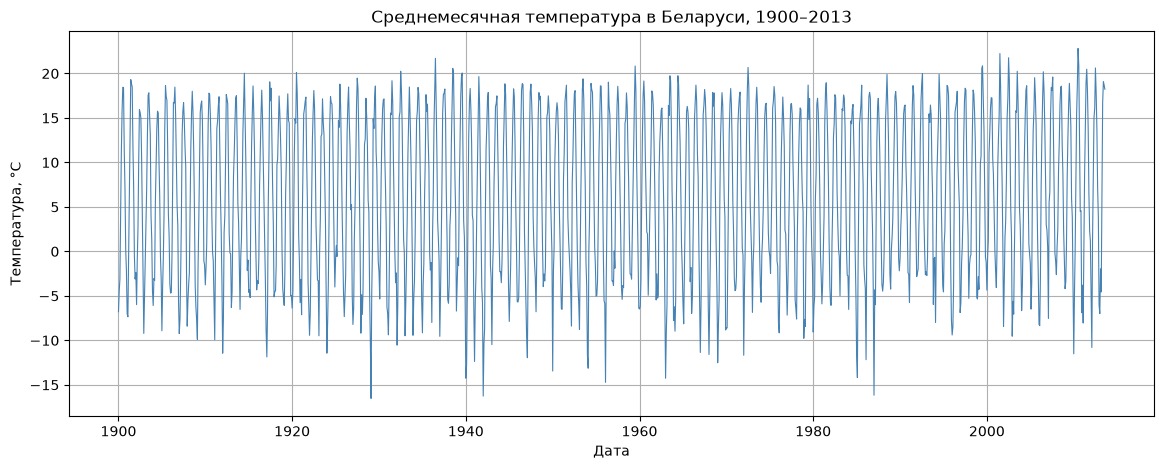

In [16]:
# Базовый график временного ряда
fig, ax = plt.subplots()
ax.plot(ts.index, ts['temperature'], lw=0.8, color='steelblue')
ax.set_title('Среднемесячная температура в Беларуси, 1900–2013')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
plt.show()

Ряд имеет ярко выраженную годовую сезонность (амплитуда ~20 °C) без сильного визуального тренда — это типичная структура для месячных температур умеренного климата.

## 2. Holdout-разбиение (80% / 20%)

Делим ряд строго по времени: первые 80% наблюдений — обучающая выборка, последние 20% — тестовая. Перемешивать временной ряд нельзя, иначе модель «подсмотрит» будущее.

Всего наблюдений: 1364
Train: 1091 (1900-01-01 — 1990-11-01)
Test:  273 (1990-12-01 — 2013-08-01)


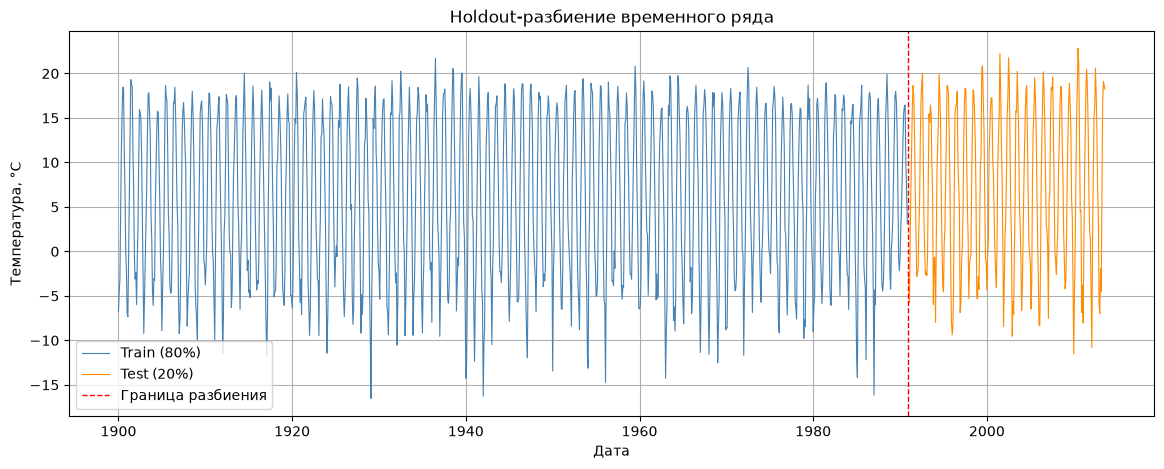

In [17]:
split_idx = int(len(ts) * 0.8)
train, test = ts.iloc[:split_idx], ts.iloc[split_idx:]

print(f'Всего наблюдений: {len(ts)}')
print(f'Train: {len(train)} ({train.index.min().date()} — {train.index.max().date()})')
print(f'Test:  {len(test)} ({test.index.min().date()} — {test.index.max().date()})')

fig, ax = plt.subplots()
ax.plot(train.index, train['temperature'], lw=0.8, label='Train (80%)', color='steelblue')
ax.plot(test.index, test['temperature'], lw=0.8, label='Test (20%)', color='darkorange')
ax.axvline(test.index[0], color='red', ls='--', lw=1, label='Граница разбиения')
ax.set_title('Holdout-разбиение временного ряда')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend()
plt.show()

Разбиение получилось по границе ~1991 года: модель обучается на данных 1900–1990 гг., а проверяется на 1990–2013 гг. — то есть прогноз всегда делается «в будущее» относительно обучающих данных.

## 3. Скользящее окно (rolling window)

Реализуем backtesting на обучающей части ряда: обучающее окно длиной **120 месяцев (10 лет)** и горизонт прогноза **12 месяцев**. Окно сдвигаем с шагом 12 месяцев, чтобы прогнозные участки не пересекались.

In [18]:
def rolling_window_split(series, train_size=120, horizon=12, step=12):
    """Генератор сплитов скользящего окна.

    На каждой итерации возвращает (train_part, test_part):
    train_part — окно длиной train_size, test_part — следующие horizon наблюдений.
    """
    for start in range(0, len(series) - train_size - horizon + 1, step):
        train_part = series.iloc[start : start + train_size]
        test_part = series.iloc[start + train_size : start + train_size + horizon]
        yield train_part, test_part

splits = list(rolling_window_split(train, train_size=120, horizon=12, step=12))
print(f'Количество сплитов на обучающей выборке: {len(splits)}')
print(f'Пример (сплит 1): train {splits[0][0].index.min().date()} — {splits[0][0].index.max().date()}, '
      f'прогноз {splits[0][1].index.min().date()} — {splits[0][1].index.max().date()}')

Количество сплитов на обучающей выборке: 80
Пример (сплит 1): train 1900-01-01 — 1909-12-01, прогноз 1910-01-01 — 1910-12-01


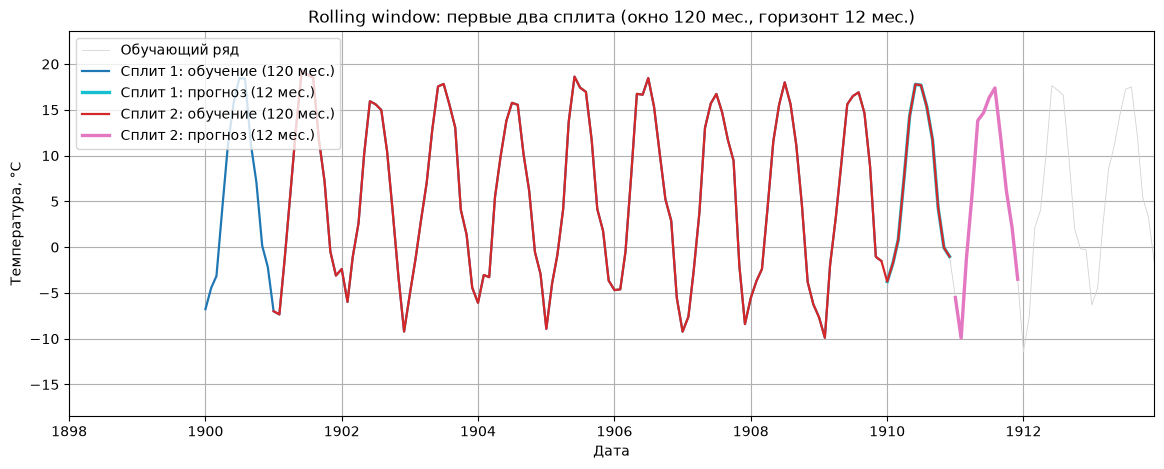

In [19]:
# Визуализация первых двух сплитов
fig, ax = plt.subplots()
ax.plot(train.index, train['temperature'], lw=0.6, color='lightgrey', label='Обучающий ряд')

colors = [('tab:blue', 'tab:cyan'), ('tab:red', 'tab:pink')]
for i, (tr, te) in enumerate(splits[:2]):
    c_tr, c_te = colors[i]
    ax.plot(tr.index, tr['temperature'], lw=1.6, color=c_tr, label=f'Сплит {i+1}: обучение (120 мес.)')
    ax.plot(te.index, te['temperature'], lw=2.4, color=c_te, label=f'Сплит {i+1}: прогноз (12 мес.)')

ax.set_title('Rolling window: первые два сплита (окно 120 мес., горизонт 12 мес.)')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend(loc='upper left')
ax.set_xlim(splits[0][0].index[0] - pd.DateOffset(years=2),
            splits[1][1].index[-1] + pd.DateOffset(years=2))
plt.show()

Каждый сплит обучает модель на 10 годах и проверяет на следующем годе; сдвиг окна на 12 месяцев даёт ~80 непересекающихся прогнозных участков. Такая схема надёжнее одиночного holdout, так как оценивает модель на многих точках отсечения.

## 4. Генерация признаков

Создаём для ряда:
- **лаг 1** (`lag_1`) — температура предыдущего месяца;
- **лаг 12** (`lag_12`) — температура того же месяца год назад (главный сезонный признак);
- **номер месяца** (`month`) — календарный признак;
- **индикатор зимы** (`is_winter`) — 1 для декабря–февраля, иначе 0.

In [20]:
feat = ts.copy()
feat['lag_1'] = feat['temperature'].shift(1)
feat['lag_12'] = feat['temperature'].shift(12)
feat['month'] = feat.index.month
feat['is_winter'] = feat['month'].isin([12, 1, 2]).astype(int)

# Первые 12 строк содержат NaN в лагах — это ожидаемо, удалим их при обучении
print('Первые строки датафрейма с признаками (до удаления NaN):')
feat.head(14)

Первые строки датафрейма с признаками (до удаления NaN):


,temperature,lag_1,lag_12,month,is_winter
dt,,,,,
1900-01-01,-6.775,NaN,NaN,1,1
1900-02-01,-4.437,-6.775,NaN,2,1
1900-03-01,-3.160,-4.437,NaN,3,0
1900-04-01,4.169,-3.160,NaN,4,0
1900-05-01,11.077,4.169,NaN,5,0
1900-06-01,15.757,11.077,NaN,6,0
1900-07-01,18.446,15.757,NaN,7,0
1900-08-01,18.414,18.446,NaN,8,0
1900-09-01,11.291,18.414,NaN,9,0


Лаги вычисляются через `shift`, то есть используют только прошлые значения ряда, — утечки данных из будущего здесь нет.

## 5. Модель и прогноз

Обучаем линейную регрессию: целевая переменная — температура, признаки — лаги и календарные признаки. Разбиение на train/test используем то же, что и в holdout (по времени), модель обучается только на обучающей части.

In [21]:
FEATURES = ['lag_1', 'lag_12', 'month', 'is_winter']
TARGET = 'temperature'

# Удаляем строки с NaN (первые 12 месяцев ряда) и повторяем holdout-разбиение по той же границе
feat_clean = feat.dropna()
split_date = test.index[0]

train_f = feat_clean.loc[feat_clean.index < split_date]
test_f = feat_clean.loc[feat_clean.index >= split_date]

X_train, y_train = train_f[FEATURES], train_f[TARGET]
X_test, y_test = test_f[FEATURES], test_f[TARGET]

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Обучение: {X_train.index.min().date()} — {X_train.index.max().date()}')
print(f'Тест:     {X_test.index.min().date()} — {X_test.index.max().date()}')

X_train: (1079, 4), X_test: (273, 4)
Обучение: 1901-01-01 — 1990-11-01
Тест:     1990-12-01 — 2013-08-01


Коэффициенты модели:
       lag_1: +0.2984
      lag_12: +0.6456
       month: -0.2855
   is_winter: -2.2677
  intercept: +2.7674


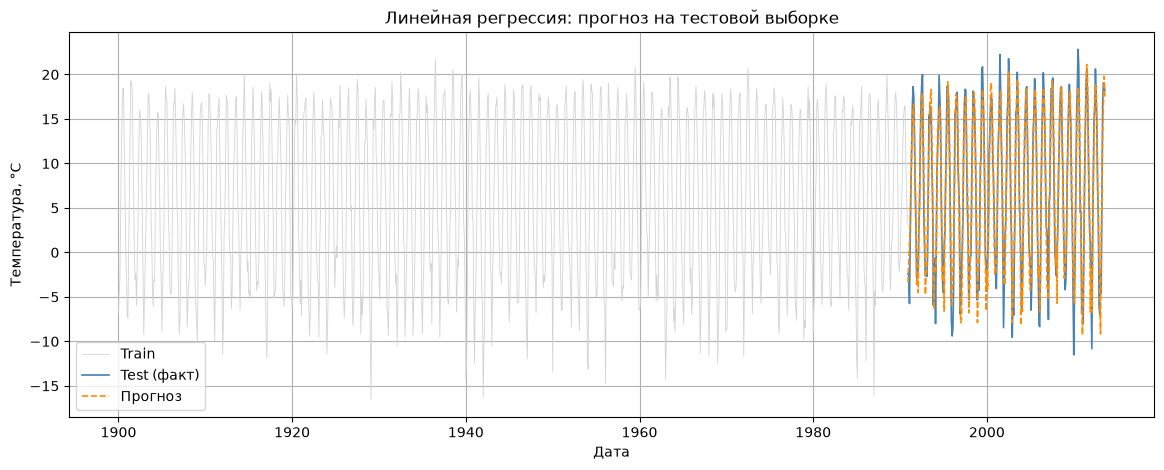

In [22]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = pd.Series(model.predict(X_test), index=X_test.index, name='forecast')

print('Коэффициенты модели:')
for name, coef in zip(FEATURES, model.coef_):
    print(f'  {name:>10}: {coef:+.4f}')
print(f'  intercept: {model.intercept_:+.4f}')

fig, ax = plt.subplots()
ax.plot(train.index, train['temperature'], lw=0.6, color='lightgrey', label='Train')
ax.plot(y_test.index, y_test, lw=1.2, color='steelblue', label='Test (факт)')
ax.plot(y_pred.index, y_pred, lw=1.2, color='darkorange', ls='--', label='Прогноз')
ax.set_title('Линейная регрессия: прогноз на тестовой выборке')
ax.set_xlabel('Дата')
ax.set_ylabel('Температура, °C')
ax.legend()
plt.show()

Модель хорошо воспроизводит сезонный ход температуры: основной вклад даёт `lag_12` (температура год назад), и линейная регрессия, несмотря на простоту, корректно описывает главную структуру ряда.

## 6. Метрики качества прогноза

Считаем MAE, RMSE и MAPE на тестовой выборке. Важный нюанс: температура в градусах Цельсия пересекает ноль, поэтому классический MAPE формально некорректен (деление на околонулевые значения). MAPE считаем только по наблюдениям с |t| > 0.5 °C и указываем долю таких наблюдений.

In [23]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# MAPE: исключаем околонулевые температуры (ряд пересекает 0 °C)
mask = y_test.abs() > 0.5
mape = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100

metrics = pd.DataFrame({
    'Метрика': ['MAE, °C', 'RMSE, °C', f'MAPE, % (по {mask.mean():.0%} наблюдений с |t| > 0.5 °C)'],
    'Значение': [round(mae, 3), round(rmse, 3), round(mape, 2)]
})
metrics

,Метрика,Значение
0,"MAE, °C",2.176
1,"RMSE, °C",2.803
2,"MAPE, % (по 96% наблюдений с |t| > 0.5 °C)",64.900


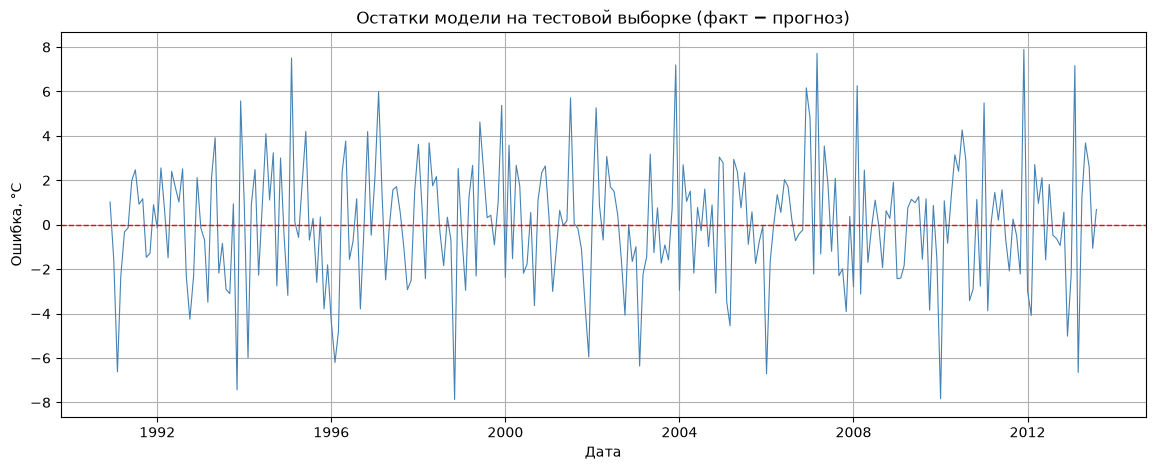

In [24]:
# Остатки прогноза
resid = y_test - y_pred
fig, ax = plt.subplots()
ax.plot(resid.index, resid, lw=0.8, color='steelblue')
ax.axhline(0, color='red', ls='--', lw=1)
ax.set_title('Остатки модели на тестовой выборке (факт − прогноз)')
ax.set_xlabel('Дата')
ax.set_ylabel('Ошибка, °C')
plt.show()

## Выводы

Простая линейная регрессия на лагах `t-1`, `t-12` и календарных признаках даёт среднюю ошибку **MAE ≈ 2.2 °C** и **RMSE ≈ 2.8 °C**: для базовой модели сезонного ряда это хороший результат — модель уверенно улавливает годовой цикл температуры. **MAPE ≈ 65%** формально велик из-за месяцев с околонулевыми температурами (деление на малые значения), поэтому для рядов, пересекающих ноль, надёжнее ориентироваться на MAE и RMSE. Остатки не содержат выраженной сезонной структуры — основную закономерность модель выучила; дальнейшее улучшение возможно за счёт добавления тренда, скользящих средних и более сложных моделей (SARIMA, градиентный бустинг).